In [1]:
import pandas as pd
import numpy as np
from scipy import stats
from statsmodels.stats.multitest import multipletests

import os
import shutil
from tqdm import tqdm

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import f_classif
from sklearn.preprocessing import StandardScaler

from sklearn.decomposition import PCA
from sklearn.linear_model import LassoCV
from sklearn.model_selection import train_test_split

from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from collections import Counter

In [2]:
data = pd.read_csv('train.csv')

In [3]:
data.shape

(35158, 2)

In [4]:
data.head()

,text,label
0,Протолитические реакции в возбужденном состоян...,llama-3.3-70b
1,Электрохимическое поведение высокоэнтропийных ...,llama-3.3-70b
2,Установление нормативных значений показателей ...,llama-3.3-70b
3,Рассматриваются природные хлориновые фотосенси...,llama-3.3-70b
4,"Оптические отклонения в изображениях, получаем...",llama-3.3-70b


Добавим метод, рассчитывающий среднее число слогов (длину слова в слогах) на текст, поскольку его аналоги отсутствуют в Profiling-UD.

In [5]:
def count_russian_syllables(text):
    if type(text) == float:
        return 0
        
    text = text.lower()
    vowels = "аеёиоуыэюя"
    
    syllables = sum(1 for char in text if char in vowels)
    words = [w for w in text.split() if w.strip()]
    word_count = len(words)
    
    if word_count == 0:
        return 0
        
    avg_syllables = syllables / word_count
    return avg_syllables


ru_text = "Мама мыла раму красивым мылом."
print(f"Среднее количество слогов (РУС): {count_russian_syllables(ru_text):.2f}")

Среднее количество слогов (РУС): 2.20


In [6]:
def get_target(x):
    if 'human' not in x.lower():
        return 'AI'
    return x


data["target"] = data['label'].apply(lambda x: get_target(x))

In [7]:
data.head()

,text,label,target
0,Протолитические реакции в возбужденном состоян...,llama-3.3-70b,AI
1,Электрохимическое поведение высокоэнтропийных ...,llama-3.3-70b,AI
2,Установление нормативных значений показателей ...,llama-3.3-70b,AI
3,Рассматриваются природные хлориновые фотосенси...,llama-3.3-70b,AI
4,"Оптические отклонения в изображениях, получаем...",llama-3.3-70b,AI


In [8]:
data.target.value_counts()

target
AI       26389
human     8769
Name: count, dtype: int64

In [9]:
data["Filename"] = [
    f"{idx}_{auth}.conllu" for idx, auth in zip(data.index, data["target"])
]

In [10]:
data['syllables'] = data['text'].apply(lambda x: count_russian_syllables(x))

In [11]:
data.head()

,text,label,target,Filename,syllables
0,Протолитические реакции в возбужденном состоян...,llama-3.3-70b,AI,0_AI.conllu,3.622222
1,Электрохимическое поведение высокоэнтропийных ...,llama-3.3-70b,AI,1_AI.conllu,3.096774
2,Установление нормативных значений показателей ...,llama-3.3-70b,AI,2_AI.conllu,3.393939
3,Рассматриваются природные хлориновые фотосенси...,llama-3.3-70b,AI,3_AI.conllu,4.227273
4,"Оптические отклонения в изображениях, получаем...",llama-3.3-70b,AI,4_AI.conllu,3.696970


In [12]:
data.columns

Index(['text', 'label', 'target', 'Filename', 'syllables'], dtype='str')

Запишем тексты в архив, чтобы затем прогнать их через Profiling-UD

In [ ]:
import io
import zipfile
import pandas as pd


def create_zip_from_dataframe(dataframe, zip_name="archive.zip"):
    zip_buffer = io.BytesIO()

    with zipfile.ZipFile(zip_buffer, "w", zipfile.ZIP_DEFLATED) as zip_file:
        for _, row in dataframe.iterrows():
            text_content = str(row["text"])
            filename = str(row["Filename"])

            if filename.endswith(".conllu"):
                filename = filename[: -len(".conllu")] + '.txt'
            zip_file.writestr(filename, text_content)
    zip_buffer.seek(0)

    with open(zip_name, "wb") as f:
        f.write(zip_buffer.getvalue())

    print(f"Архив {zip_name} успешно создан!")


create_zip_from_dataframe(data, "ru_texts.zip")

Исследуем получившиеся признаки на взаимную корреляцию, чтобы удалить лишние перед подачей в SVM-классификатор

In [13]:
profiling_ud_results_path = 'AIGTxt_profiling_ud_21119.csv'

In [14]:
profiling_df = pd.read_table(profiling_ud_results_path)

In [15]:
profiling_df.shape

(35158, 129)

In [16]:
import re
pattern = re.compile(r'(\d+?)_([^\.]+)(?:\.conllu)', re.I)

def extract_class(x):
    return pattern.search(x).group(2)

print(extract_class('2413_Human-written.conllu'))
print(extract_class('0_human.conllu'))

Human-written
human


In [17]:
profiling_df['target'] = profiling_df['Filename'].apply(lambda x: extract_class(x))

/tmp/ipykernel_1586029/827259542.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  profiling_df['target'] = profiling_df['Filename'].apply(lambda x: extract_class(x))


In [18]:
profiling_df['target'].value_counts()

target
AI       26389
human     8769
Name: count, dtype: int64

Количество объектов в классах совпадают с исходниками.

In [19]:
profiling_df.head()

,Filename,n_sentences,n_tokens,tokens_per_sent,char_per_tok,ttr_lemma_chunks_100,ttr_lemma_chunks_200,ttr_form_chunks_100,ttr_form_chunks_200,upos_dist_ADJ,...,subordinate_proposition_dist,subordinate_post,subordinate_pre,avg_subordinate_chain_len,subordinate_dist_1,subordinate_dist_2,subordinate_dist_3,subordinate_dist_4,subordinate_dist_5,target
0,25774_AI.conllu,4,78,19.500000,8.197183,0.00,0.0,0.00,0.0,16.666667,...,20.000000,100.000000,0.000000,1.0,100.0,0.0,0.0,0.0,0.0,AI
1,14254_AI.conllu,3,68,22.666667,7.666667,0.00,0.0,0.00,0.0,16.176471,...,66.666667,100.000000,0.000000,1.2,80.0,20.0,0.0,0.0,0.0,AI
2,11231_AI.conllu,4,90,22.500000,7.951807,0.00,0.0,0.00,0.0,14.444444,...,75.000000,83.333333,16.666667,1.0,100.0,0.0,0.0,0.0,0.0,AI
3,13694_human.conllu,7,213,30.428571,7.628272,0.81,0.0,0.87,0.0,20.187793,...,41.666667,100.000000,0.000000,1.0,100.0,0.0,0.0,0.0,0.0,human
4,12715_AI.conllu,4,83,20.750000,8.175676,0.00,0.0,0.00,0.0,16.867470,...,33.333333,100.000000,0.000000,1.0,100.0,0.0,0.0,0.0,0.0,AI


Проверка на число предложений в тексте.

In [20]:
data[data.Filename.str.contains('25774_AI.conllu')].text.values[0].split('.')

['Данная статья посвящена актуальной проблеме профилактики конфликтных отношений в трудовых коллективах',
 ' В работе рассматриваются психологические механизмы возникновения конфликтов на рабочем месте и предлагается комплексная программа психологической профилактики, направленная на создание благоприятного психологического климата в организации',
 ' Программа сопровождения включает в себя мероприятия по развитию коммуникативных навыков сотрудников, формированию навыков разрешения конфликтов, а также по укреплению team-building',
 ' Авторы статьи обосновывают необходимость внедрения такой программы и приводят примеры ее успешной реализации в различных организациях',
 '']

### 1. Объединим два датасета для проверки на взаимную корреляцию

In [21]:
X = data[['Filename', 'syllables']]

In [22]:
X.head()

,Filename,syllables
0,0_AI.conllu,3.622222
1,1_AI.conllu,3.096774
2,2_AI.conllu,3.393939
3,3_AI.conllu,4.227273
4,4_AI.conllu,3.696970


In [23]:
merged_df = pd.merge(X, profiling_df, on='Filename', how="left")

In [24]:
merged_df.shape

(35158, 131)

In [25]:
merged_df.head()

,Filename,syllables,n_sentences,n_tokens,tokens_per_sent,char_per_tok,ttr_lemma_chunks_100,ttr_lemma_chunks_200,ttr_form_chunks_100,ttr_form_chunks_200,...,subordinate_proposition_dist,subordinate_post,subordinate_pre,avg_subordinate_chain_len,subordinate_dist_1,subordinate_dist_2,subordinate_dist_3,subordinate_dist_4,subordinate_dist_5,target
0,0_AI.conllu,3.622222,5,99,19.800000,8.054945,0.0,0.0,0.0,0.0,...,28.571429,100.000000,0.000000,1.0,100.0,0.0,0.0,0.0,0.0,AI
1,1_AI.conllu,3.096774,3,71,23.666667,7.822581,0.0,0.0,0.0,0.0,...,50.000000,100.000000,0.000000,1.5,50.0,50.0,0.0,0.0,0.0,AI
2,2_AI.conllu,3.393939,3,72,24.000000,7.878788,0.0,0.0,0.0,0.0,...,50.000000,66.666667,33.333333,1.0,100.0,0.0,0.0,0.0,0.0,AI
3,3_AI.conllu,4.227273,2,48,24.000000,9.795455,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,AI
4,4_AI.conllu,3.696970,4,77,19.250000,8.522388,0.0,0.0,0.0,0.0,...,55.555556,80.000000,20.000000,1.0,100.0,0.0,0.0,0.0,0.0,AI


In [26]:
merged_df = merged_df[merged_df.syllables > 0]
merged_df.shape

(35145, 131)

In [27]:
significant_cols = {'sign': 0, 'not_sign': 0}
alpha = 0.05

valid_cols = [col for col in merged_df.columns if 'Filename' not in col and 'target' not in col]
p_values = []
analyzed_cols = []

for col in valid_cols:
    data_to_test = merged_df[col].dropna()
    
    if len(data_to_test) >= 3 and not (data_to_test == data_to_test.iloc[0]).all():
        _, p_value = stats.shapiro(data_to_test)
        p_values.append(p_value)
        analyzed_cols.append(col)

# Применяем поправку Холма (метод 'holm')
if p_values:
    reject, corrected_p_vals, _, _ = multipletests(p_values, alpha=alpha, method='holm')

    # 3. Считаем результаты
    significant_cols['sign'] = int(np.sum(reject))
    significant_cols['not_sign'] = len(reject) - significant_cols['sign']

print(significant_cols)

/.venv/lib/python3.13/site-packages/scipy/stats/_axis_nan_policy.py:592: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 35145.
  res = hypotest_fun_out(*samples, **kwds)


{'sign': 129, 'not_sign': 0}


Все данные в колонках не распределены нормально, применяем корреляцию Спирмена.

In [28]:
corr_df = merged_df.drop(columns=["Filename", "target"])
corr_matrix = corr_df.corr(method='spearman').abs()

upper_tri = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

threshold = 0.70

to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > threshold)]

flat_upper = upper_tri.stack()
high_corr_pairs = flat_upper[flat_upper > threshold].sort_values(
    ascending=False
)

print("Пары сильно коррелирующих признаков (отсортировано по убыванию):")
for (row, col), val in high_corr_pairs.items():
    print(f"  • {row} <-> {col}: {val:.2f}")

print(f"\nРекомендуется удалить следующие признаки (всего {len(to_drop)}):")
print('\n'.join(to_drop))

Пары сильно коррелирующих признаков (отсортировано по убыванию):
  • tokens_per_sent <-> dep_dist_root: 1.00
  • upos_dist_PUNCT <-> dep_dist_punct: 1.00
  • ttr_lemma_chunks_200 <-> ttr_form_chunks_200: 1.00
  • aux_mood_dist_Ind <-> aux_form_dist_Fin: 1.00
  • principal_proposition_dist <-> subordinate_proposition_dist: 1.00
  • subj_pre <-> subj_post: 1.00
  • ttr_lemma_chunks_100 <-> ttr_form_chunks_100: 1.00
  • upos_dist_VERB <-> avg_token_per_clause: 1.00
  • upos_dist_DET <-> dep_dist_det: 0.99
  • verbs_tense_dist_Past <-> verbs_tense_dist_Pres: 0.99
  • upos_dist_CCONJ <-> dep_dist_cc: 0.99
  • upos_dist_ADP <-> dep_dist_case: 0.99
  • upos_dist_SCONJ <-> dep_dist_mark: 0.98
  • aux_tense_dist_Past <-> aux_mood_dist_Ind: 0.95
  • aux_tense_dist_Past <-> aux_form_dist_Fin: 0.95
  • upos_dist_NUM <-> dep_dist_nummod: 0.94
  • avg_prepositional_chain_len <-> prep_dist_2: 0.92
  • prep_dist_1 <-> prep_dist_2: 0.91
  • upos_dist_AUX <-> dep_dist_aux:pass: 0.91
  • avg_prepositiona

Чистим и сохраняем датасет 

In [29]:
df_cleaned = merged_df.drop(columns=to_drop)
df_cleaned.shape

(35145, 93)

In [30]:
df_cleaned.head()

,Filename,syllables,n_sentences,tokens_per_sent,ttr_lemma_chunks_100,ttr_lemma_chunks_200,upos_dist_ADJ,upos_dist_ADP,upos_dist_ADV,upos_dist_AUX,...,dep_dist_obl,dep_dist_orphan,dep_dist_parataxis,subordinate_post,avg_subordinate_chain_len,subordinate_dist_1,subordinate_dist_3,subordinate_dist_4,subordinate_dist_5,target
0,0_AI.conllu,3.622222,5,19.800000,0.0,0.0,14.141414,12.121212,2.020202,1.010101,...,2.020202,0.0,1.010101,100.000000,1.0,100.0,0.0,0.0,0.0,AI
1,1_AI.conllu,3.096774,3,23.666667,0.0,0.0,18.309859,9.859155,0.000000,1.408451,...,2.816901,0.0,0.000000,100.000000,1.5,50.0,0.0,0.0,0.0,AI
2,2_AI.conllu,3.393939,3,24.000000,0.0,0.0,15.277778,9.722222,0.000000,2.777778,...,2.777778,0.0,1.388889,66.666667,1.0,100.0,0.0,0.0,0.0,AI
3,3_AI.conllu,4.227273,2,24.000000,0.0,0.0,27.083333,8.333333,0.000000,0.000000,...,0.000000,0.0,2.083333,0.000000,0.0,0.0,0.0,0.0,0.0,AI
4,4_AI.conllu,3.696970,4,19.250000,0.0,0.0,10.389610,7.792208,2.597403,0.000000,...,5.194805,0.0,0.000000,80.000000,1.0,100.0,0.0,0.0,0.0,AI


In [31]:
df_cleaned[['subordinate_dist_3', 'subordinate_dist_4', 'subordinate_dist_5']].describe()

,subordinate_dist_3,subordinate_dist_4,subordinate_dist_5
count,35145.000000,35145.000000,35145.000000
mean,0.743472,0.032357,0.002608
std,5.832839,1.058607,0.284621
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000
max,100.000000,100.000000,33.333333


array([[<Axes: title={'center': 'subordinate_dist_3'}>,
        <Axes: title={'center': 'subordinate_dist_4'}>],
       [<Axes: title={'center': 'subordinate_dist_5'}>, <Axes: >]],
      dtype=object)

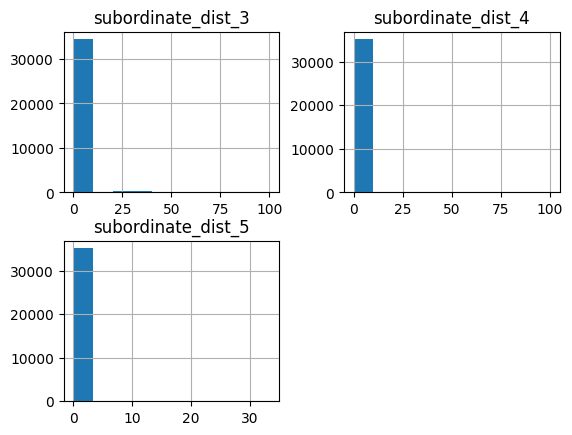

In [32]:
df_cleaned[['subordinate_dist_3', 'subordinate_dist_4', 'subordinate_dist_5']].hist()

### 2. Построим несколько моделей для индекса удобочитаемости

Введём адаитацию FRE Оборневой как оринтировочный таргет для налей регрессии

In [33]:
# Формула Оборневой: 206.835 - (1.3 * ASL) - (60.1 * ASW)
# где ASL — средняя длина предложения в словах (tokens_per_sent)
# а ASW — среднее число слогов в слове (syllables)

df_cleaned['fre_oborneva'] = 206.835 - (1.3 * df_cleaned['tokens_per_sent']) - (60.1 * df_cleaned['syllables'])
df_cleaned.head()

,Filename,syllables,n_sentences,tokens_per_sent,ttr_lemma_chunks_100,ttr_lemma_chunks_200,upos_dist_ADJ,upos_dist_ADP,upos_dist_ADV,upos_dist_AUX,...,dep_dist_orphan,dep_dist_parataxis,subordinate_post,avg_subordinate_chain_len,subordinate_dist_1,subordinate_dist_3,subordinate_dist_4,subordinate_dist_5,target,fre_oborneva
0,0_AI.conllu,3.622222,5,19.800000,0.0,0.0,14.141414,12.121212,2.020202,1.010101,...,0.0,1.010101,100.000000,1.0,100.0,0.0,0.0,0.0,AI,-36.600556
1,1_AI.conllu,3.096774,3,23.666667,0.0,0.0,18.309859,9.859155,0.000000,1.408451,...,0.0,0.000000,100.000000,1.5,50.0,0.0,0.0,0.0,AI,-10.047796
2,2_AI.conllu,3.393939,3,24.000000,0.0,0.0,15.277778,9.722222,0.000000,2.777778,...,0.0,1.388889,66.666667,1.0,100.0,0.0,0.0,0.0,AI,-28.340758
3,3_AI.conllu,4.227273,2,24.000000,0.0,0.0,27.083333,8.333333,0.000000,0.000000,...,0.0,2.083333,0.000000,0.0,0.0,0.0,0.0,0.0,AI,-78.424091
4,4_AI.conllu,3.696970,4,19.250000,0.0,0.0,10.389610,7.792208,2.597403,0.000000,...,0.0,0.000000,80.000000,1.0,100.0,0.0,0.0,0.0,AI,-40.377879


In [34]:
df_cleaned.describe()

,syllables,n_sentences,tokens_per_sent,ttr_lemma_chunks_100,ttr_lemma_chunks_200,upos_dist_ADJ,upos_dist_ADP,upos_dist_ADV,upos_dist_AUX,upos_dist_CCONJ,...,dep_dist_obl,dep_dist_orphan,dep_dist_parataxis,subordinate_post,avg_subordinate_chain_len,subordinate_dist_1,subordinate_dist_3,subordinate_dist_4,subordinate_dist_5,fre_oborneva
count,35145.000000,35145.000000,35145.000000,35145.000000,35145.000000,35145.000000,35145.000000,35145.000000,35145.000000,35145.000000,...,35145.000000,35145.000000,35145.000000,35145.000000,35145.000000,35145.000000,35145.000000,35145.000000,35145.000000,35145.000000
mean,3.349968,4.505676,22.116398,0.136036,0.038164,15.296040,9.551816,1.201703,0.314156,4.733980,...,5.020693,0.004669,0.809437,88.377517,1.045308,82.661602,0.743472,0.032357,0.002608,-23.249407
std,0.299142,2.338581,5.635958,0.285696,0.151707,4.292814,2.605664,1.331856,0.630303,2.106645,...,2.320655,0.071639,1.067654,27.317941,0.365657,30.511859,5.832839,1.058607,0.284621,17.654597
min,0.029126,1.000000,6.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-228.928415
25%,3.170213,3.000000,18.800000,0.000000,0.000000,12.440191,7.843137,0.000000,0.000000,3.292181,...,3.409091,0.000000,0.000000,100.000000,1.000000,75.000000,0.000000,0.000000,0.000000,-34.065000
50%,3.355932,4.000000,21.400000,0.000000,0.000000,15.238095,9.523810,1.052632,0.000000,4.651163,...,4.901961,0.000000,0.000000,100.000000,1.000000,100.000000,0.000000,0.000000,0.000000,-23.276765
75%,3.535714,5.000000,24.333333,0.000000,0.000000,18.064516,11.235955,1.904762,0.000000,6.086957,...,6.500000,0.000000,1.333333,100.000000,1.166667,100.000000,0.000000,0.000000,0.000000,-12.530517
max,5.277778,38.000000,192.000000,0.930000,0.815000,40.740741,30.000000,15.789474,5.813953,16.666667,...,20.000000,2.666667,11.538462,100.000000,4.000000,100.000000,100.000000,100.000000,33.333333,174.144515


<Axes: xlabel='n_sentences', ylabel='Count'>

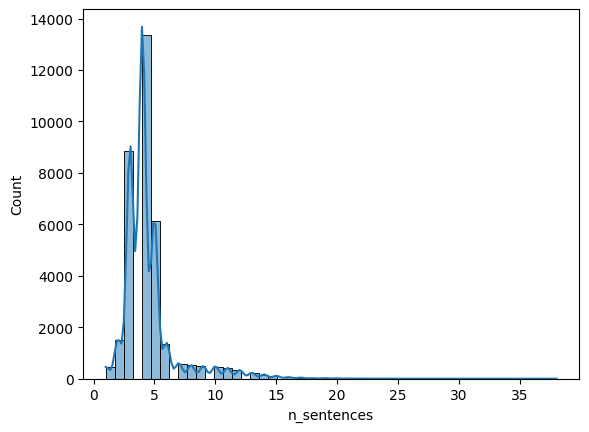

In [35]:
sns.histplot(data=df_cleaned, x="n_sentences", kde=True, bins=50)

<Axes: xlabel='log_norm_n_sentences', ylabel='Count'>

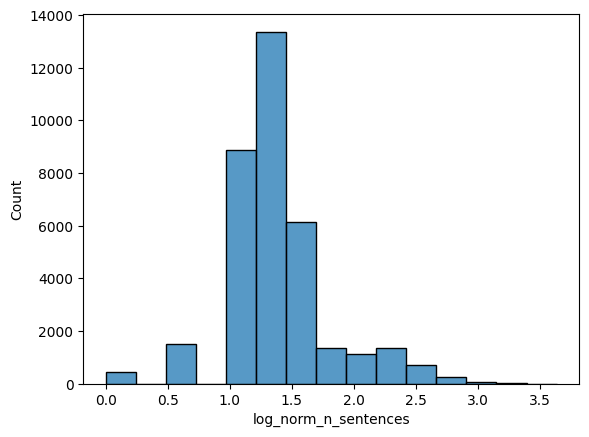

In [36]:
df_cleaned['log_norm_n_sentences'] = np.log(df_cleaned['n_sentences'])

sns.histplot(data=df_cleaned, x="log_norm_n_sentences", bins=15, kde=False)

Чило предложений в тексте имеет логнормальное распределение.

<Axes: xlabel='tokens_per_sent', ylabel='Count'>

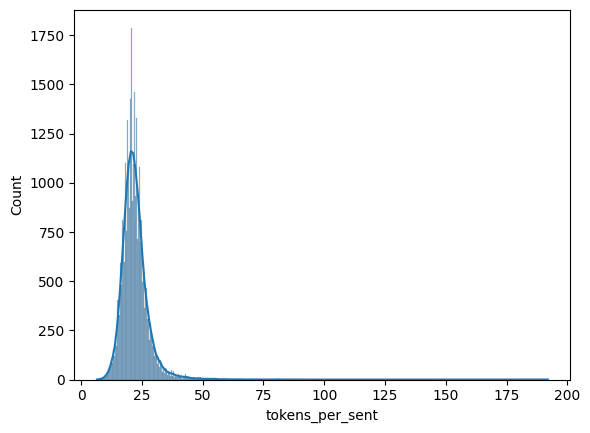

In [37]:
sns.histplot(data=df_cleaned, x="tokens_per_sent", kde=True)

In [38]:
X = df_cleaned.drop(columns=['target', 'fre_oborneva', 'Filename', 'tokens_per_sent', 'syllables'])
y = df_cleaned['fre_oborneva']

print(f"Размерность исходных данных: {X.shape}, {y.shape}")

Размерность исходных данных: (35145, 90), (35145,)


#### Факторный анализ (обучение без учителя)

Нормализация оставшихся признаков

In [39]:
# Масштабирование признаков (критично для Lasso и PCA)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

За основной алгоритм возьмём метод главных компонент и применим его на тех признаках, которые не входят в оценку сложности И.В.Оборневой.

Выделяем одну главную компоненту, которая соберет максимум дисперсии.

In [40]:
pca = PCA(n_components=1, random_state=42)
latent_factor = pca.fit_transform(X_scaled).flatten()

Проверяем корреляцию латентного фактора со старым индексом.

In [41]:
correlation = np.corrcoef(latent_factor, y)[0, 1]
print(f"Корреляция 1-й компоненты PCA с Флеш-Оборневой: {correlation:.4f}")

Корреляция 1-й компоненты PCA с Флеш-Оборневой: 0.1999


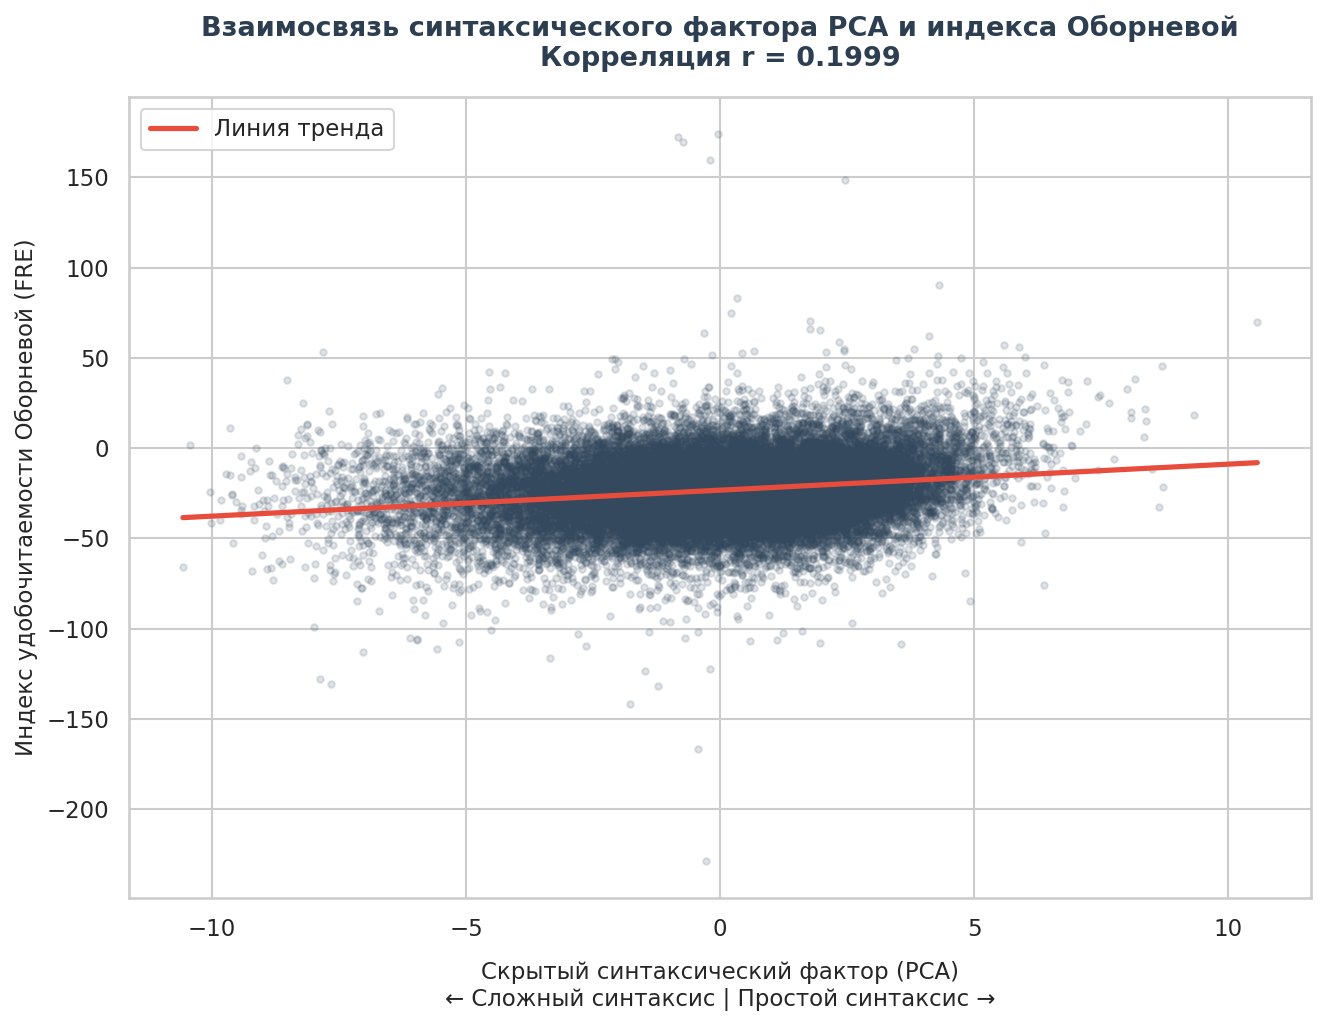

In [42]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 7), dpi=150)

sns.regplot(
    x=latent_factor,
    y=y,
    scatter_kws={"alpha": 0.15, "color": "#34495e", "s": 10},
    line_kws={"color": "#e74c3c", "linewidth": 2.5, "label": "Линия тренда"},
)

plt.title(
    f"Взаимосвязь синтаксического фактора PCA и индекса Оборневой\nКорреляция r = {correlation:.4f}",
    fontsize=13,
    pad=15,
    weight="bold",
    color="#2c3e50",
)

plt.xlabel(
    "Скрытый синтаксический фактор (PCA)\n← Сложный синтаксис | Простой синтаксис →",
    fontsize=11,
    labelpad=10,
)
plt.ylabel("Индекс удобочитаемости Оборневой (FRE)", fontsize=11)
plt.legend(loc="upper left")

plt.tight_layout()
plt.show()

Сильной взаимосвязи со старым индексом не наблюдается. Возможно, что метод PCA оценивает сложность иначе.

In [45]:
# Инвертируем знак, если корреляция отрицательная (чтобы сохранить логику "выше = проще")
if correlation < 0:
    latent_factor = -latent_factor

# Нормализуем индекс от 0 до 100 для удобства интерпретации
min_val, max_val = latent_factor.min(), latent_factor.max()
df_cleaned['my_readability_score_pca'] = 100 * (latent_factor - min_val) / (max_val - min_val)
df_cleaned.head()

,Filename,syllables,n_sentences,tokens_per_sent,ttr_lemma_chunks_100,ttr_lemma_chunks_200,upos_dist_ADJ,upos_dist_ADP,upos_dist_ADV,upos_dist_AUX,...,subordinate_post,avg_subordinate_chain_len,subordinate_dist_1,subordinate_dist_3,subordinate_dist_4,subordinate_dist_5,target,fre_oborneva,log_norm_n_sentences,my_readability_score_pca
0,0_AI.conllu,3.622222,5,19.800000,0.0,0.0,14.141414,12.121212,2.020202,1.010101,...,100.000000,1.0,100.0,0.0,0.0,0.0,AI,-36.600556,1.609438,56.269669
1,1_AI.conllu,3.096774,3,23.666667,0.0,0.0,18.309859,9.859155,0.000000,1.408451,...,100.000000,1.5,50.0,0.0,0.0,0.0,AI,-10.047796,1.098612,50.807867
2,2_AI.conllu,3.393939,3,24.000000,0.0,0.0,15.277778,9.722222,0.000000,2.777778,...,66.666667,1.0,100.0,0.0,0.0,0.0,AI,-28.340758,1.098612,58.781460
3,3_AI.conllu,4.227273,2,24.000000,0.0,0.0,27.083333,8.333333,0.000000,0.000000,...,0.000000,0.0,0.0,0.0,0.0,0.0,AI,-78.424091,0.693147,31.632605
4,4_AI.conllu,3.696970,4,19.250000,0.0,0.0,10.389610,7.792208,2.597403,0.000000,...,80.000000,1.0,100.0,0.0,0.0,0.0,AI,-40.377879,1.386294,48.723946


Значения обычного FRE и PCA отличаются друг от друга. Скорее всего, первая главная компонента уловила скрытую структуру русского синтаксиса и морфологии, которую стандартный FRE (даже русифицированный) вообще не замечает.

#### Оценка моделей

Нормализуем оба индекса от 0 до 100, чтобы их можно было сравнивать. Предполагаем, что чем выше PCA, тем проще.

In [46]:
df_cleaned['fre_norm'] = (df_cleaned['fre_oborneva'] - df_cleaned['fre_oborneva'].min()) / (df_cleaned['fre_oborneva'].max() - df_cleaned['fre_oborneva'].min()) * 100
df_cleaned['pca_norm'] = (df_cleaned['my_readability_score_pca'] - df_cleaned['my_readability_score_pca'].min()) / (df_cleaned['my_readability_score_pca'].max() - df_cleaned['my_readability_score_pca'].min()) * 100

In [47]:
df_cleaned.head()

,Filename,syllables,n_sentences,tokens_per_sent,ttr_lemma_chunks_100,ttr_lemma_chunks_200,upos_dist_ADJ,upos_dist_ADP,upos_dist_ADV,upos_dist_AUX,...,subordinate_dist_1,subordinate_dist_3,subordinate_dist_4,subordinate_dist_5,target,fre_oborneva,log_norm_n_sentences,my_readability_score_pca,fre_norm,pca_norm
0,0_AI.conllu,3.622222,5,19.800000,0.0,0.0,14.141414,12.121212,2.020202,1.010101,...,100.0,0.0,0.0,0.0,AI,-36.600556,1.609438,56.269669,47.715400,56.269669
1,1_AI.conllu,3.096774,3,23.666667,0.0,0.0,18.309859,9.859155,0.000000,1.408451,...,50.0,0.0,0.0,0.0,AI,-10.047796,1.098612,50.807867,54.302982,50.807867
2,2_AI.conllu,3.393939,3,24.000000,0.0,0.0,15.277778,9.722222,0.000000,2.777778,...,100.0,0.0,0.0,0.0,AI,-28.340758,1.098612,58.781460,49.764606,58.781460
3,3_AI.conllu,4.227273,2,24.000000,0.0,0.0,27.083333,8.333333,0.000000,0.000000,...,0.0,0.0,0.0,0.0,AI,-78.424091,0.693147,31.632605,37.339229,31.632605
4,4_AI.conllu,3.696970,4,19.250000,0.0,0.0,10.389610,7.792208,2.597403,0.000000,...,100.0,0.0,0.0,0.0,AI,-40.377879,1.386294,48.723946,46.778268,48.723946


Считаем абсолютную разницу между оценками

In [48]:
df_cleaned['model_diff'] = df_cleaned['fre_norm'] - df_cleaned['pca_norm']

#### 1. FRE говорит "Просто" (ближе к 100), PCA говорит "Сложно" (ближе к 0)

In [50]:
dispute_simple_fre = df_cleaned.sort_values(by='model_diff', ascending=False).head(5)
for idx, row in dispute_simple_fre.iterrows():
    print(f"ID: {idx} | FRE Norm: {row['fre_norm']:.1f} | PCA Norm: {row['pca_norm']:.1f}")
    print(f"Text: {data[data.Filename == row.Filename]['text'].values[0]}")
    print("-" * 40)

ID: 23929 | FRE Norm: 70.0 | PCA Norm: 13.0
Text: Рассмотрены основные тенденции в области шинного корда и его адгезии к резине в начале 21 века.
----------------------------------------
ID: 10562 | FRE Norm: 57.2 | PCA Norm: 0.7
Text: Дана общая характеристика Конвенции о правах ребенка. Затронута проблема ювенальной юстиции. 
----------------------------------------
ID: 13857 | FRE Norm: 66.1 | PCA Norm: 9.7
Text: В статье представлен опыт по разработке и внедрению интегрированной системы
----------------------------------------
ID: 24008 | FRE Norm: 59.5 | PCA Norm: 4.4
Text: Исследовано состояние и перспективы развития производства этилена в мире и России.
----------------------------------------
ID: 18898 | FRE Norm: 99.6 | PCA Norm: 46.1
Text: Обзор summarizes the latest randomized controlled trials (RCTs) published in 2023 investigating the complex interplay between hemostasis and blood transfusion. The review analyzes the impact of various blood products, including plasma, on c

- Для FRE предложения короткие
- PCA нашёл в текстах употребление пассивного залога, кратких причастий, генетивов.

#### 2. FRE говорит "Сложно", PCA говорит "Просто"

In [51]:
dispute_complex_fre = df_cleaned.sort_values(by='model_diff', ascending=True).head(5)
for idx, row in dispute_complex_fre.iterrows():
    print(f"ID: {idx} | FRE Norm: {row['fre_norm']:.1f} | PCA Norm: {row['pca_norm']:.1f}")
    print(f"Text: {data[data.Filename == row.Filename]['text'].values[0]}")
    print("-" * 40)

ID: 34642 | FRE Norm: 0.0 | PCA Norm: 48.7
Text: Методы микроскопии разного разрешения применены для регистрации динамики следующих процессов, происходящих с системами доставки лекарственных соединений in vitro и ex vivo: изменение во времени структуры систем доставки противоопухолевого антибиотика доксорубицина на базе пористых ватеритов карбоната кальция, допированных полианионом декстрансульфатом, и гидроксиапатитов под влиянием плазмы крови (оценивали при помощи сканирующего электронного микроскопа); увеличение в пять раз размеров альгинатных гранул - потенциальных носителей ранозаживляющих препаратов - в среде экссудата (раневой жидкости) (наблюдали в оптическом микроскопе); пространственное распределение флуоресцентно-меченого белка по объему носителя - частиц пористого ватерита CaCO3 (представлено в виде оптических срезов, полученных при помощи лазерного сканирующего конфокального микроскопа); воздействие увеличивающейся до 2 μg/ml концентрации доксорубицина, инкапсулированного 

- Для FRE тексты оказались длинными
- Возможно, что PCA не видит в предложениях запутанных синтаксических конструкций

#### Выводы

- FRE измеряет когнитивную нагрузку на оперативную память (сложно удерживать в голове смысл длинного предложения, даже если оно линейное (к примеру, сложносочинённое))
- PCA измеряет грамматическую запутанность (например, иерархию придаточных предложений)

#### Попробуем взвесить обе оценки

Дадим FRE вес 0.6 (за когнитивную длину), а PCA вес 0.4 (за структурную сложность).

In [52]:
df_cleaned['final_readability_index'] = (df_cleaned['fre_norm'] * 0.6) + (df_cleaned['pca_norm'] * 0.4)
df_cleaned.head()

,Filename,syllables,n_sentences,tokens_per_sent,ttr_lemma_chunks_100,ttr_lemma_chunks_200,upos_dist_ADJ,upos_dist_ADP,upos_dist_ADV,upos_dist_AUX,...,subordinate_dist_4,subordinate_dist_5,target,fre_oborneva,log_norm_n_sentences,my_readability_score_pca,fre_norm,pca_norm,model_diff,final_readability_index
0,0_AI.conllu,3.622222,5,19.800000,0.0,0.0,14.141414,12.121212,2.020202,1.010101,...,0.0,0.0,AI,-36.600556,1.609438,56.269669,47.715400,56.269669,-8.554269,51.137107
1,1_AI.conllu,3.096774,3,23.666667,0.0,0.0,18.309859,9.859155,0.000000,1.408451,...,0.0,0.0,AI,-10.047796,1.098612,50.807867,54.302982,50.807867,3.495114,52.904936
2,2_AI.conllu,3.393939,3,24.000000,0.0,0.0,15.277778,9.722222,0.000000,2.777778,...,0.0,0.0,AI,-28.340758,1.098612,58.781460,49.764606,58.781460,-9.016854,53.371348
3,3_AI.conllu,4.227273,2,24.000000,0.0,0.0,27.083333,8.333333,0.000000,0.000000,...,0.0,0.0,AI,-78.424091,0.693147,31.632605,37.339229,31.632605,5.706623,35.056580
4,4_AI.conllu,3.696970,4,19.250000,0.0,0.0,10.389610,7.792208,2.597403,0.000000,...,0.0,0.0,AI,-40.377879,1.386294,48.723946,46.778268,48.723946,-1.945678,47.556539


In [53]:
correlation = np.corrcoef(df_cleaned['final_readability_index'], y)[0, 1]
print(f"Корреляция взвешенной метрики с Флеш-Оборневой: {correlation:.4f}")

Корреляция взвешенной метрики с Флеш-Оборневой: 0.6163


Наша новая взвешенная модель поймала суть двух предыдущих моделей.

Посмотрим на то, какие из признаков упрощают/усложняют текст по мнению PCA

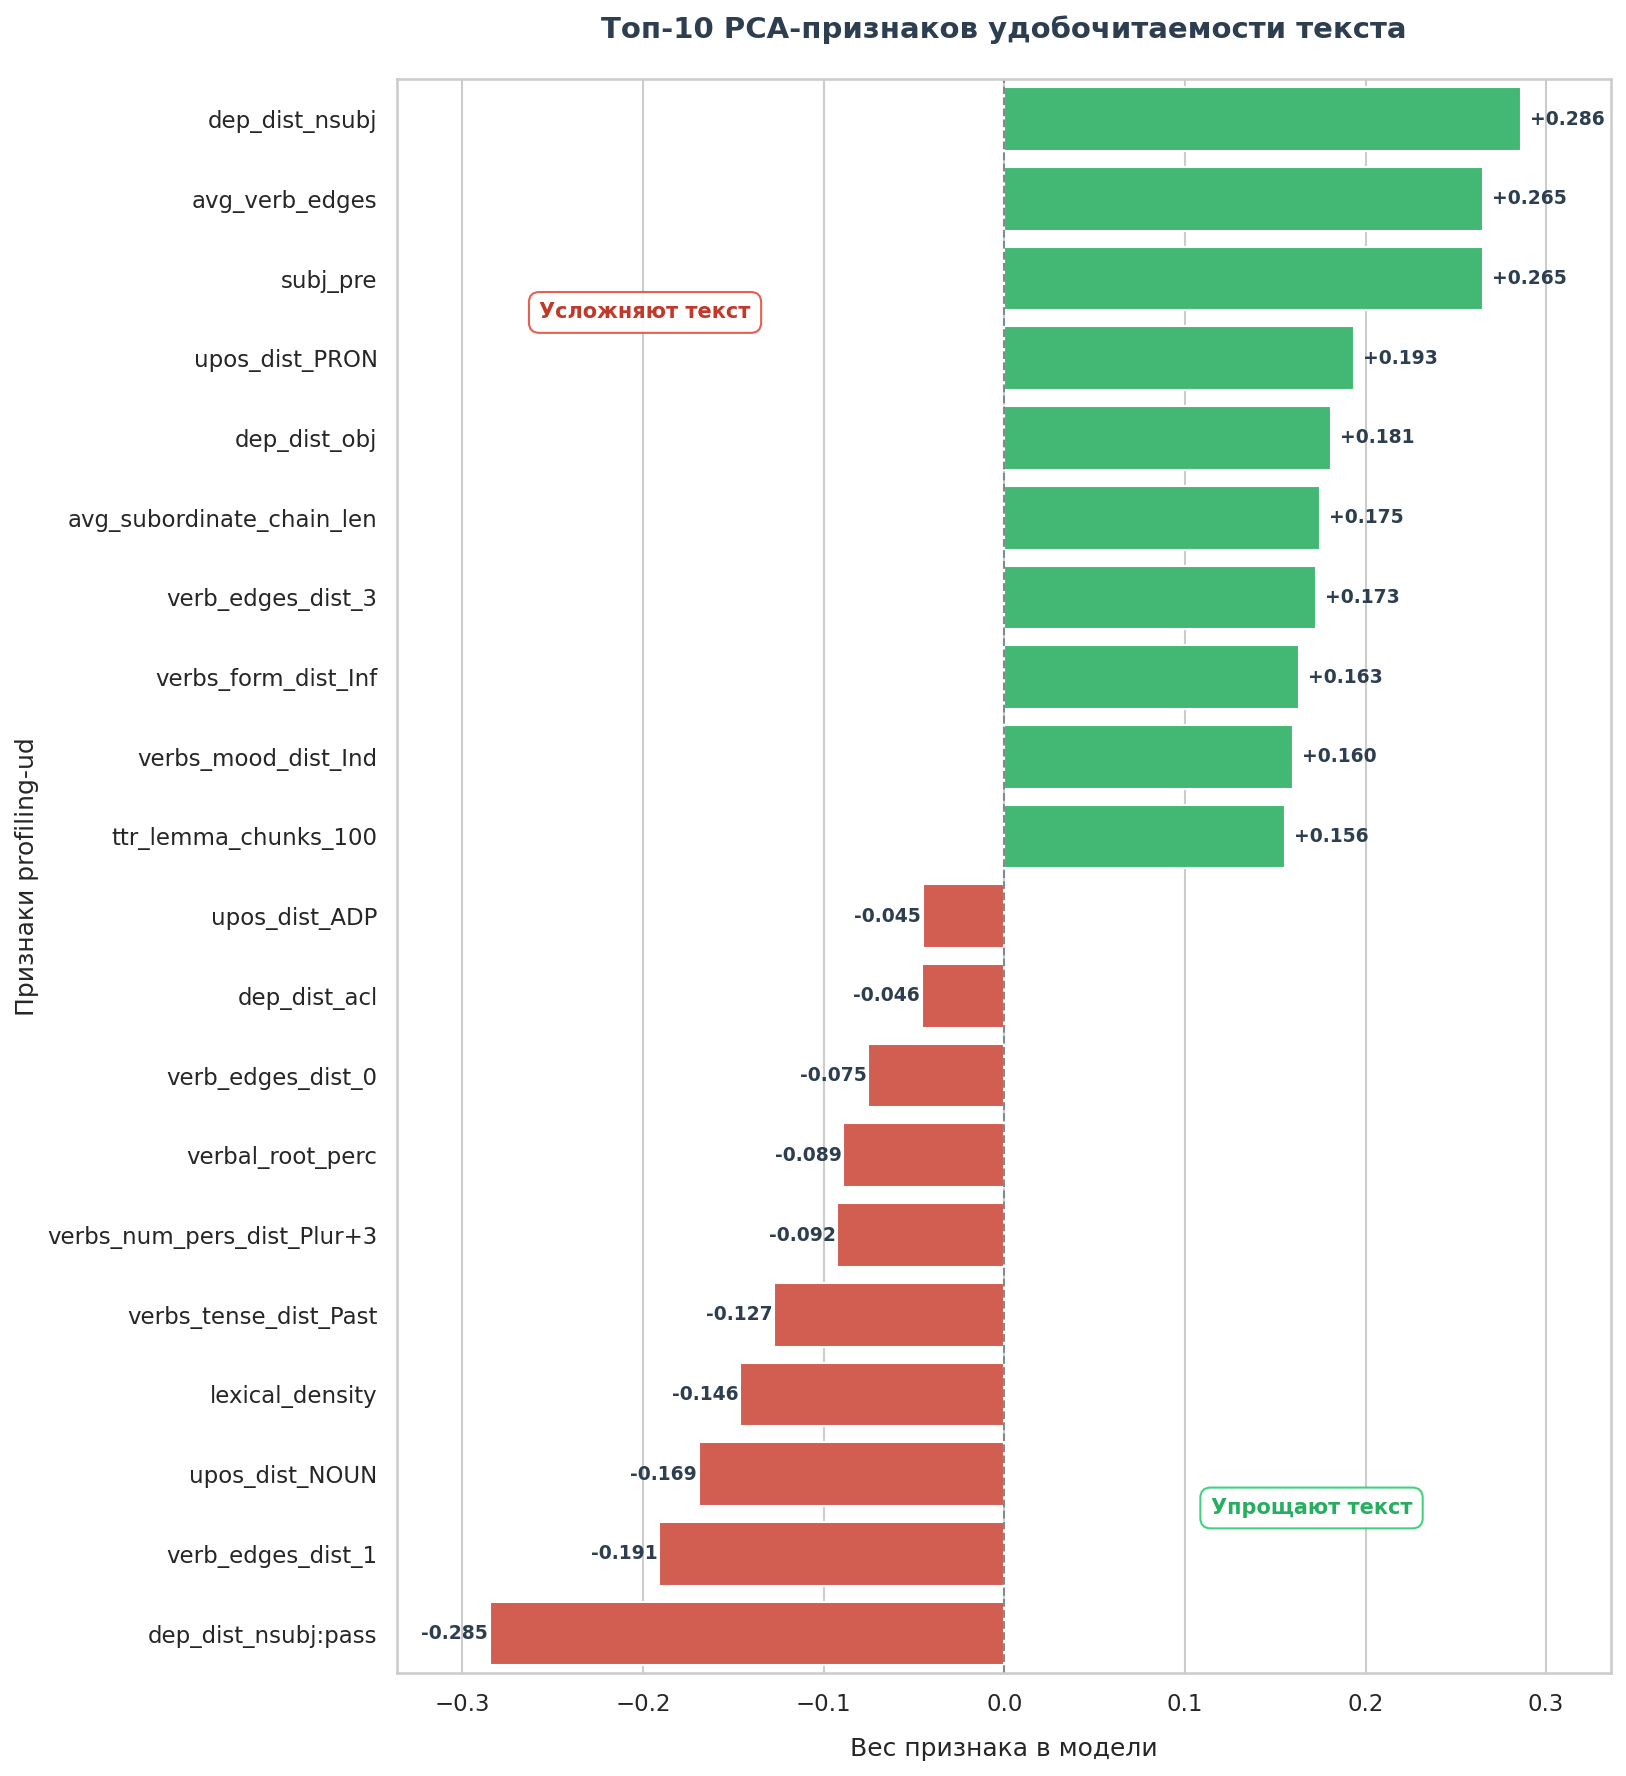

In [57]:
def plot_pca_readability_weights(pca, X_filtered, top_n=10):
    """Автоматически извлекает исходные веса PCA и строит горизонтальный barplot.

    pca: обученный объект PCA(n_components=1)
    X_filtered: pandas.DataFrame с фичами до масштабирования (нужен для имён
    колонок) top_n: сколько топовых фич брать с каждого полюса (по умолчанию 10)
    """
    # 1. Получаем веса для первой главной компоненты (индекс 0)
    pca_weights = pd.Series(pca.components_[0], index=X_filtered.columns)

    # 2. Отбираем топ-N упрощающих (исходно положительных) и топ-N усложняющих (исходно отрицательных) признаков
    top_simplicity = pca_weights.sort_values(ascending=False).head(top_n)
    top_complexity = pca_weights.sort_values(ascending=True).head(top_n)

    # Объединяем их в один DataFrame для визуализации
    df_plot = pd.concat([top_simplicity, top_complexity]).to_frame(name="Weight")
    df_plot.index.name = "Feature"
    df_plot = df_plot.reset_index()

    # Удаляем дубликаты, если они возникли
    df_plot = df_plot.drop_duplicates(subset=["Feature"])

    # Сортируем по убыванию веса, чтобы график шел от самых "простых" к самым "сложным"
    df_plot = df_plot.sort_values(by="Weight", ascending=False)

    # 3. Настройка стиля и размера
    sns.set_theme(style="whitegrid")
    plt.figure(figsize=(11, 0.6 * len(df_plot)), dpi=150)

    # Динамическая палитра: зеленый для положительных, красный для отрицательных весов
    colors = ["#2ecc71" if w > 0 else "#e74c3c" for w in df_plot["Weight"]]

    # 4. Построение графика
    barplot = sns.barplot(
        x="Weight",
        y="Feature",
        data=df_plot,
        palette=colors,
        hue="Feature",
        legend=False,
    )

    # 5. Добавляем текстовые метки с точными значениями весов на столбцы
    for i, row in enumerate(df_plot.itertuples()):
        # Смещение текста зависит от знака веса (подбираем отступы, чтобы текст не обрезался)
        x_pos = row.Weight + 0.005 if row.Weight > 0 else row.Weight - 0.038
        plt.text(
            x_pos,
            i,
            f"{row.Weight:+.3f}",
            va="center",
            fontsize=9,
            weight="bold",
            color="#2c3e50",
        )

    # 6. Оформление графического пространства
    plt.title(
        f"Топ-{top_n} PCA-признаков удобочитаемости текста",
        fontsize=14,
        pad=20,
        weight="bold",
        color="#2c3e50",
    )
    plt.xlabel("Вес признака в модели", fontsize=12, labelpad=10)
    plt.ylabel("Признаки profiling-ud", fontsize=12)

    # Проводим центральную осевую линию
    plt.axvline(0, color="#7f8c8d", linestyle="--", linewidth=1)

    # Автоматически расширяем границы оси X, чтобы текст меток не вылезал за края
    max_w = df_plot["Weight"].abs().max()
    plt.xlim(-max_w - 0.05, max_w + 0.05)

    plt.text(
        max_w * 0.4, 
        len(df_plot) - 2.5,
        "Упрощают текст",
        fontsize=10,
        color="#27ae60",
        weight="bold",
        bbox=dict(facecolor="white", alpha=0.9, edgecolor="#2ecc71", boxstyle="round,pad=0.5")
    )
    plt.text(
        -max_w * 0.9, 
        2.5,
        "Усложняют текст",
        fontsize=10,
        color="#c0392b",
        weight="bold",
        bbox=dict(facecolor="white", alpha=0.9, edgecolor="#e74c3c", boxstyle="round,pad=0.5")
    )

    plt.tight_layout()
    plt.show()


# Вызов с отфильтрованной матрицей признаков (без признаков длины)
plot_pca_readability_weights(pca, X, top_n=10)

Что упрощает текст:
- Инфинитивы, изъявительное наклонение, применение активного залога - всё это это признак действия, динамики и понятной структуры целей;
- Прямой порядок слов (например, подлежащие $->$ сказуемое) также упрощает текст;
- Наличие предикативных узлов, в которых действие выражено личным глаголом, управляющим субъектом и объектом;
- Лексическое разнообразие: богатый и динамичный словарный запас, что может свидетельствовать о научно-популярном жанре текстов.

Что усложняет текст:
- Придаточные определительные и разного рода обороты;
- Пассивность и безобъектность текстов, глаголы превращаются в изолированные краткие формы (Исследовано. Обнаружено.);
- `upos_dist_ADP`: Доля предлогов (ADP). Чем больше предлогов `upos_dist_ADP` (в, на, под влиянием, в области, при помощи), тем больше падежей и тем сложнее синтаксис.

**Вывод:** Текст становится простым за счёт активных глаголов и местоимений, а сложный содержит в себе обилие пассивного залога, множество существительных и бесконечных предлогов.